# JS06 – Regresi: Praktikum 1
## Regresi Linier Sederhana dengan Dataset E-Commerce

**Tujuan praktikum**

1. Membaca dan memahami struktur dataset pelanggan e-commerce.
2. Melakukan eksplorasi data (EDA) untuk melihat hubungan antara perilaku pelanggan dan pengeluaran tahunan.
3. Membangun model **regresi linier sederhana** dengan `statsmodels` (OLS).
4. Menganalisis **residual** untuk memeriksa asumsi dan kualitas model.
5. Mengevaluasi model pada data uji menggunakan **R², MSE, RMSE, dan MAE**.

**Dataset:** `dataset.csv` berisi 500 pelanggan dengan kolom identitas (`Email`, `Address`, `Avatar`), empat fitur perilaku (`Avg. Session Length`, `Time on App`, `Time on Website`, `Length of Membership`), dan target `Yearly Amount Spent` (USD).

> Notebook ini mengikuti alur Praktikum 1 pada modul, dengan tambahan evaluasi metrik dan interpretasi hasil. Seluruh angka dihasilkan saat notebook dijalankan.

### 0. Import library

Library yang dipakai:

- `numpy` dan `pandas` untuk manipulasi data.
- `matplotlib` dan `seaborn` untuk visualisasi.
- `scikit-learn` untuk pembagian data dan metrik evaluasi.
- `statsmodels` untuk estimasi regresi linier dengan output statistik lengkap.

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 50)

print("Python     :", platform.python_version())
print("NumPy      :", np.__version__)
print("pandas     :", pd.__version__)
print("seaborn    :", sns.__version__)

Python     : 3.12.3
NumPy      : 2.5.4
pandas     : 3.0.6
seaborn    : 0.13.2


### 1. Membaca data

File `dataset.csv` diletakkan di direktori yang sama dengan notebook. Setelah dibaca, kita cek lima baris pertama dan ukuran data.

In [2]:
data = pd.read_csv("dataset.csv")

print("Ukuran data:", data.shape)
data.head()

Ukuran data: (500, 8)


,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


### 2. Pemahaman terhadap data

Tahap ini melihat tipe data, jumlah nilai non-null, statistik deskriptif, serta memastikan tidak ada nilai kosong atau baris duplikat.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB


In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg. Session Length,500.0,33.053194,0.992563,29.532429,32.341822,33.082008,33.711985,36.139662
Time on App,500.0,12.052488,0.994216,8.508152,11.388153,11.983231,12.753850,15.126994
Time on Website,500.0,37.060445,1.010489,33.913847,36.349257,37.069367,37.716432,40.005182
Length of Membership,500.0,3.533462,0.999278,0.269901,2.930450,3.533975,4.126502,6.922689
Yearly Amount Spent,500.0,499.314038,79.314782,256.670582,445.038277,498.887875,549.313828,765.518462


In [5]:
ringkasan_kualitas = pd.DataFrame({
    "Jumlah nilai kosong": data.isna().sum(),
    "Persentase kosong (%)": (data.isna().mean() * 100).round(2),
    "Jumlah nilai unik": data.nunique(),
})
ringkasan_kualitas

,Jumlah nilai kosong,Persentase kosong (%),Jumlah nilai unik
Email,0,0.0,500
Address,0,0.0,500
Avatar,0,0.0,138
Avg. Session Length,0,0.0,500
Time on App,0,0.0,500
Time on Website,0,0.0,500
Length of Membership,0,0.0,500
Yearly Amount Spent,0,0.0,500


In [6]:
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 0


### 3. Visualisasi dan analisis korelasi

Pairplot digunakan untuk melihat pola hubungan antara setiap fitur perilaku dengan `Yearly Amount Spent`. Heatmap korelasi membantu memilih fitur yang paling berkaitan dengan target.

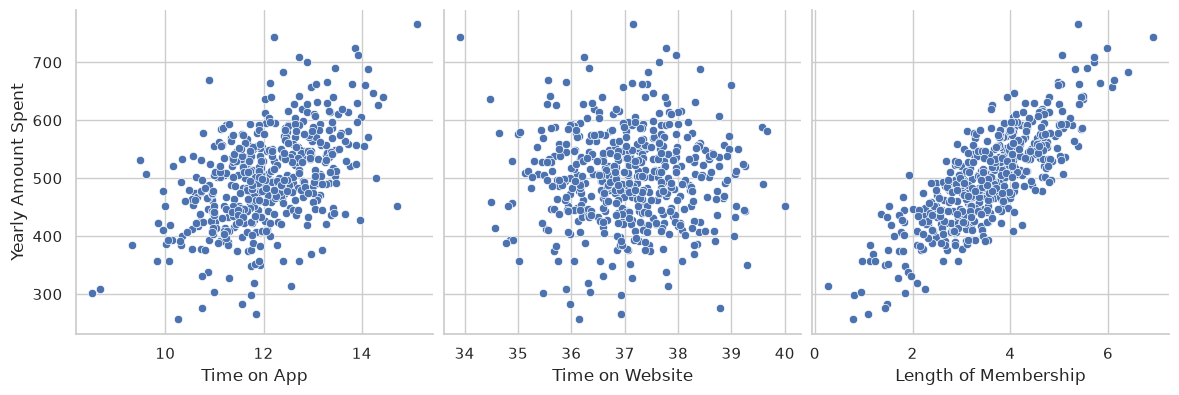

In [7]:
sns.pairplot(
    data,
    x_vars=["Time on App", "Time on Website", "Length of Membership"],
    y_vars="Yearly Amount Spent",
    height=4,
    aspect=1,
    kind="scatter",
)
plt.show()

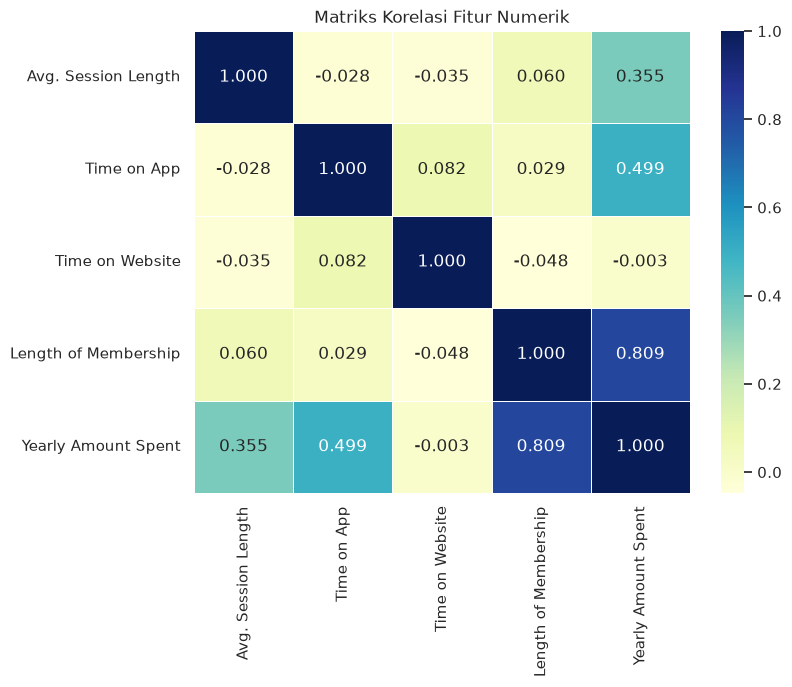

Yearly Amount Spent     1.000000
Length of Membership    0.809084
Time on App             0.499328
Avg. Session Length     0.355088
Time on Website        -0.002641
Name: Yearly Amount Spent, dtype: float64

In [8]:
numeric_data = data.select_dtypes(include=np.number)
corr = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="YlGnBu", annot=True, fmt=".3f", linewidths=0.5)
plt.title("Matriks Korelasi Fitur Numerik")
plt.show()

corr["Yearly Amount Spent"].sort_values(ascending=False)

**Interpretasi sementara.** Dari heatmap, `Length of Membership` memiliki korelasi positif paling kuat terhadap `Yearly Amount Spent`, diikuti `Time on App`. `Time on Website` hampir tidak berkorelasi dengan target. Karena itu, model regresi sederhana pada praktikum ini menggunakan `Length of Membership` sebagai satu-satunya variabel bebas.

### 4. Regresi linier sederhana

Model yang dibentuk adalah

$$\hat{y} = \beta_0 + \beta_1 x,$$

dengan $x$ = `Length of Membership` dan $y$ = `Yearly Amount Spent`.

Data dibagi menjadi **70% data latih** dan **30% data uji** menggunakan `random_state=100` agar hasil dapat direproduksi.

In [9]:
from sklearn.model_selection import train_test_split

X = data["Length of Membership"]
y = data["Yearly Amount Spent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    test_size=0.3,
    random_state=100,
)

print("Jumlah data latih :", len(X_train))
print("Jumlah data uji   :", len(X_test))

Jumlah data latih : 350
Jumlah data uji   : 150


In [10]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

print("Koefisien model:")
print(lr.params)
lr.summary()

Koefisien model:
const                   265.248299
Length of Membership     66.301522
dtype: float64


<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                            
===============================================================================
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Tue, 20 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         21:08:50   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  265.2483      9.120     29.083      0.000     247.311     283.186
Length of Membership    66.3015      2.501     26.512      0.000      61.383      71.220
==============================================================================
Omnibus:                        1.643   Durbin-Watson:                   1.929
Prob(Omnibus):                  0.440   Jarque-Bera (JB):                1.471
Skew:                          -0.013   Prob(JB):                        0.479
Kurtosis:                       2.683   Cond. No.                         14.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Output `summary()` memuat koefisien, standard error, nilai t, p-value, R², dan uji F. Koefisien `const` adalah intersep, sedangkan koefisien `Length of Membership` adalah kemiringan garis regresi.

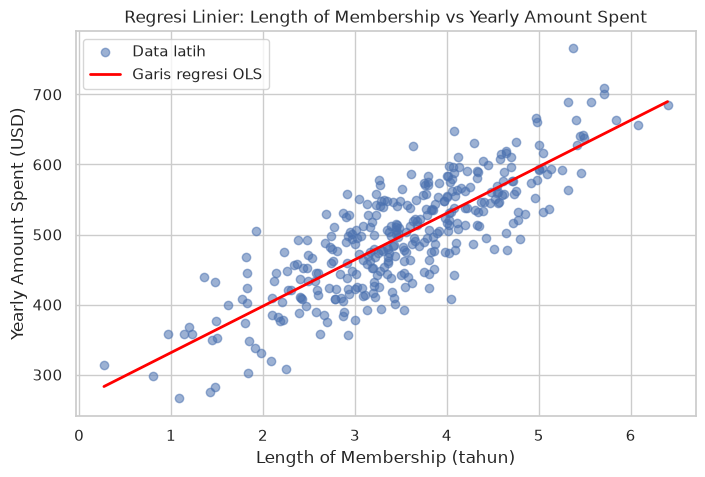

In [11]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.55, label="Data latih")

x_line = np.linspace(X_train.min(), X_train.max(), 100)
y_line = lr.params["const"] + lr.params["Length of Membership"] * x_line
plt.plot(x_line, y_line, color="red", linewidth=2, label="Garis regresi OLS")

plt.title("Regresi Linier: Length of Membership vs Yearly Amount Spent")
plt.xlabel("Length of Membership (tahun)")
plt.ylabel("Yearly Amount Spent (USD)")
plt.legend()
plt.show()

### 5. Analisis residual

Residual didefinisikan sebagai

$$e_i = y_i - \hat{y}_i.$$

Residual yang baik memiliki rata-rata mendekati nol, tidak membentuk pola sistematis terhadap $x$, dan kira-kira berdistribusi normal. Histogram dan scatter plot residual digunakan untuk memeriksa hal tersebut.

In [12]:
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred

print("Statistik residual data latih:")
print(res.describe())

Statistik residual data latih:
count    3.500000e+02
mean     4.466269e-14
std      4.668621e+01
min     -1.248920e+02
25%     -2.910151e+01
50%     -1.176037e+00
75%      3.362104e+01
max      1.437275e+02
dtype: float64


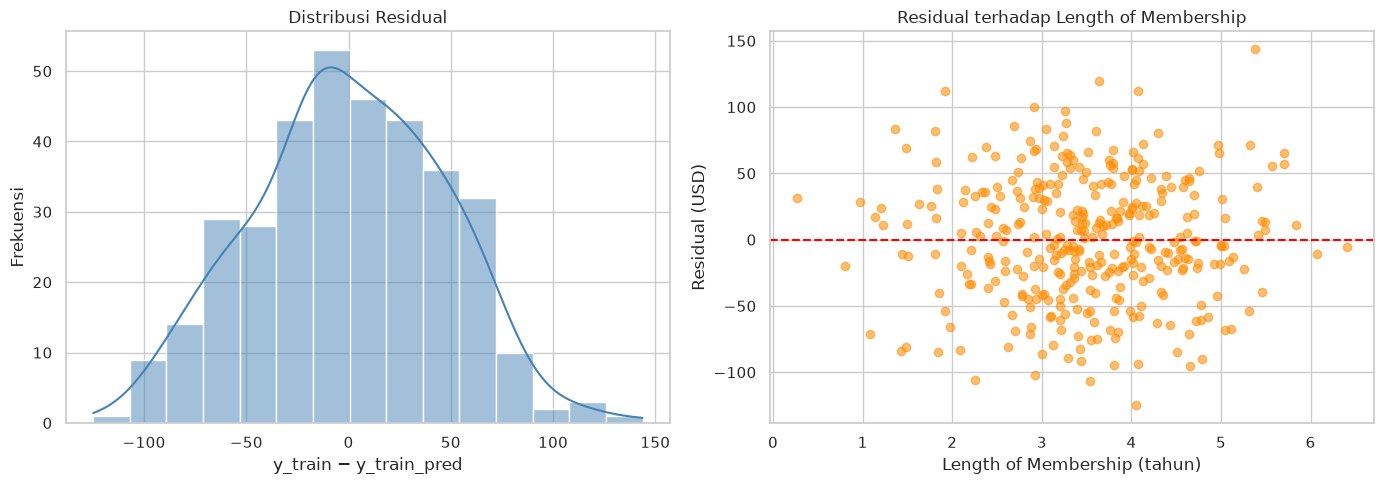

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(res, bins=15, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi Residual")
axes[0].set_xlabel("y_train − y_train_pred")
axes[0].set_ylabel("Frekuensi")

axes[1].scatter(X_train, res, alpha=0.55, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Residual terhadap Length of Membership")
axes[1].set_xlabel("Length of Membership (tahun)")
axes[1].set_ylabel("Residual (USD)")

plt.tight_layout()
plt.show()

### 6. Prediksi dan evaluasi pada data uji

Model diuji pada 30% data yang tidak dipakai saat pelatihan. Metrik yang dipakai:

- **R²** — proporsi variansi target yang dapat dijelaskan model. Nilai 1 berarti sempurna.
- **MSE** — rata-rata kuadrat error; sensitif terhadap error besar.
- **RMSE** — akar MSE, satuannya sama dengan target (USD).
- **MAE** — rata-rata error absolut, lebih mudah ditafsirkan dan tidak terlalu sensitif terhadap outlier.

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

metrik = pd.DataFrame({
    "Metrik": ["R²", "MSE (USD²)", "RMSE (USD)", "MAE (USD)"],
    "Data latih": [r2_train, mse_train, rmse_train, mae_train],
    "Data uji": [r2_test, mse_test, rmse_test, mae_test],
})

metrik["Data latih"] = metrik["Data latih"].map(lambda v: f"{v:,.4f}")
metrik["Data uji"] = metrik["Data uji"].map(lambda v: f"{v:,.4f}")
metrik

,Metrik,Data latih,Data uji
0,R²,0.6688,0.6119
1,MSE (USD²),"2,173.3747","2,171.3702"
2,RMSE (USD),46.6195,46.5980
3,MAE (USD),37.8638,36.8673


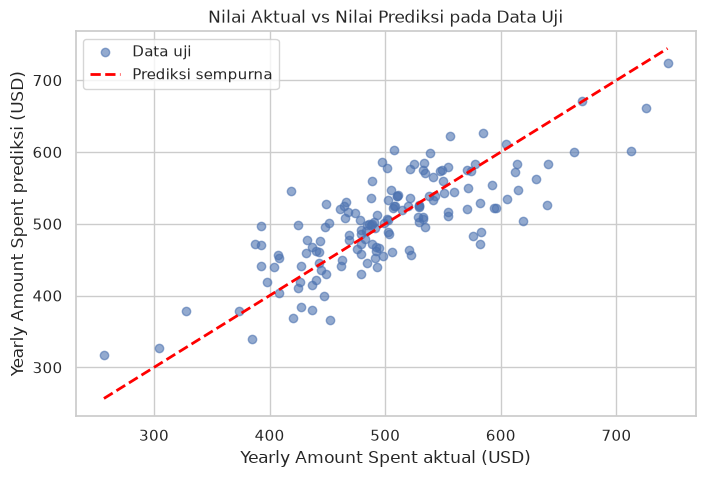

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_test_pred, alpha=0.6, label="Data uji")

batas = [
    min(y_test.min(), y_test_pred.min()),
    max(y_test.max(), y_test_pred.max()),
]
plt.plot(batas, batas, color="red", linestyle="--", linewidth=2, label="Prediksi sempurna")

plt.title("Nilai Aktual vs Nilai Prediksi pada Data Uji")
plt.xlabel("Yearly Amount Spent aktual (USD)")
plt.ylabel("Yearly Amount Spent prediksi (USD)")
plt.legend()
plt.show()

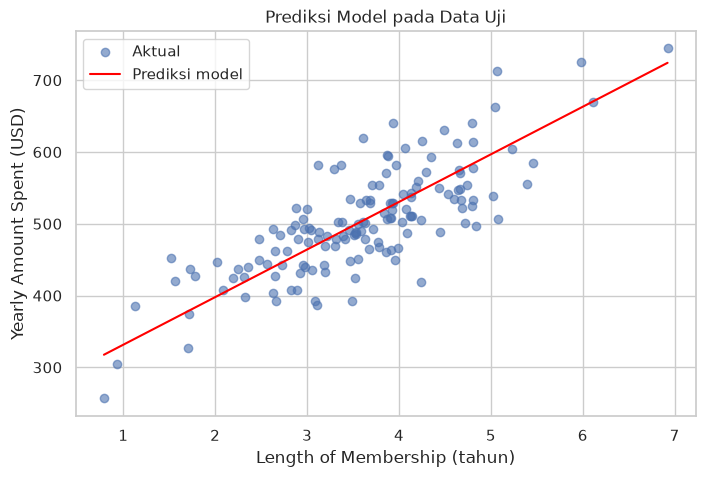

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.6, label="Aktual")
order = np.argsort(X_test.to_numpy())
plt.plot(
    X_test.to_numpy()[order],
    y_test_pred.to_numpy()[order],
    color="red",
    linewidth=1.5,
    label="Prediksi model",
)
plt.title("Prediksi Model pada Data Uji")
plt.xlabel("Length of Membership (tahun)")
plt.ylabel("Yearly Amount Spent (USD)")
plt.legend()
plt.show()

### 7. Interpretasi hasil

Persamaan regresi yang diperoleh adalah

$$\hat{y} = 265{,}2483 + 66{,}3015 \times \text{Length of Membership}.$$

Artinya, setiap tambahan **satu tahun** keanggotaan dikaitkan dengan kenaikan pengeluaran tahunan sekitar **66,30 USD** pada model ini. Intersep 265,25 USD adalah nilai prediksi ketika `Length of Membership = 0`; nilai ini berada di luar rentang data yang wajar sehingga tidak perlu ditafsirkan secara berlebihan.

Nilai R² data latih sekitar **0,669**, sedangkan R² data uji sekitar **0,612**. Selisihnya tidak terlalu besar, sehingga model cukup stabil dan tidak menunjukkan overfitting yang serius. Namun, R² data uji 0,612 berarti sekitar **61,2%** variansi pengeluaran tahunan dapat dijelaskan oleh lama keanggotaan; sisanya dijelaskan faktor lain yang tidak dimasukkan ke model.

Residual memiliki rata-rata mendekati nol dan histogram yang kira-kira simetris. Scatter residual tidak menunjukkan pola lengkung yang jelas, sehingga asumsi linearitas cukup wajar. Meskipun demikian, terdapat beberapa residual ekstrem, yang menunjukkan bahwa satu fitur saja belum cukup untuk memprediksi pengeluaran pelanggan secara akurat.

**Keterbatasan model**

- Hanya memakai satu fitur, sehingga variabel seperti `Time on App`, `Time on Website`, dan `Avg. Session Length` belum dimanfaatkan.
- Korelasi tidak sama dengan kausalitas.
- Model linear tidak menangkap interaksi atau hubungan non-linear.
- Evaluasi hanya pada satu pembagian data; validasi silang akan memberikan estimasi yang lebih stabil.

### 8. Kesimpulan

1. `Length of Membership` memiliki korelasi positif paling kuat dengan `Yearly Amount Spent` (r ≈ 0,809).
2. Model regresi linier sederhana menghasilkan $\hat{y} = 265{,}2483 + 66{,}3015x$ dengan R² data uji ≈ 0,612.
3. Residual berpusat di sekitar nol tanpa pola yang jelas, tetapi masih terdapat error yang cukup besar.
4. Model cukup stabil antara data latih dan data uji, namun masih dapat ditingkatkan dengan menambahkan fitur lain atau memakai model regresi berganda.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS06 – Regresi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi
- `statsmodels` – Ordinary Least Squares. https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html
- `scikit-learn` – Linear Models dan Regression Metrics. https://scikit-learn.org/stable/modules/linear_model.html
- `seaborn` – Visualizing statistical relationships. https://seaborn.pydata.org/tutorial/relational.html